<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 24: Graphical Model Sampling and Probabilistic Inference

In this notebook, we construct a medical Bayesian network modeling **Smoking (S)**, **Lung Disease (L)**, **Persistent Cough (C)**, and **Positive X-Ray (X)**.

### Network Structure and Conditional Probability Tables (CPTs):
1. **Smoking (S)**: $P(S = 1) = 0.40$ (representing 40% smokers).
2. **Lung Disease (L)** conditioned on Smoking:
   - $P(L = 1 | S = 0) = 0.10$
   - $P(L = 1 | S = 1) = 0.30$
3. **Persistent Cough (C)** conditioned on Lung Disease:
   - $P(C = 1 | L = 0) = 0.20$
   - $P(C = 1 | L = 1) = 0.80$
4. **Positive X-Ray (X)** conditioned on Lung Disease:
   - $P(X = 1 | L = 0) = 0.05$
   - $P(X = 1 | L = 1) = 0.90$

We will perform exact inference using Variable Elimination, approximate inference using Rejection Sampling, visualize sampling convergence, and compare results in a comparative summary table.

In [1]:
# Install necessary libraries
!pip install -q pgmpy networkx pandas numpy matplotlib

## Setup: Define the Bayesian Network
Here we construct the Bayesian Network using `pgmpy` and visualize its DAG structure.

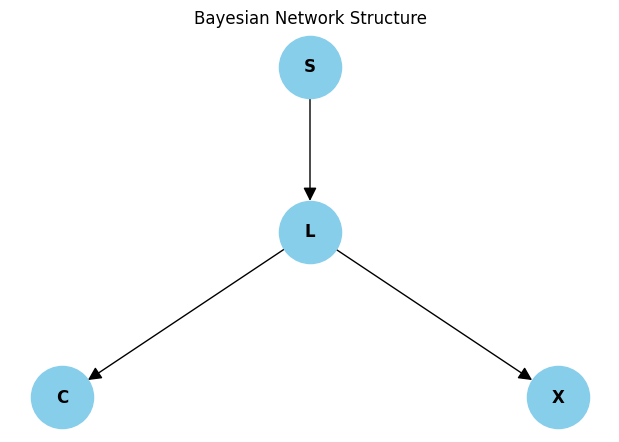

In [3]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.sampling import BayesianModelSampling

# Define the network structure
# S: Smoking, L: Lung Disease, C: Cough, X: X-ray
model = DiscreteBayesianNetwork([
    ('S', 'L'),
    ('L', 'C'),
    ('L', 'X')
])

# Define Conditional Probability Distributions (CPDs)
cpd_s = TabularCPD(variable='S', variable_card=2, values=[[0.60], [0.40]])

cpd_l = TabularCPD(
    variable='L',
    variable_card=2,
    values=[[0.90, 0.70],  # L=0 given S=0, S=1
            [0.10, 0.30]], # L=1 given S=0, S=1
    evidence=['S'],
    evidence_card=[2]
)

cpd_c = TabularCPD(
    variable='C',
    variable_card=2,
    values=[[0.80, 0.20],  # C=0 given L=0, L=1
            [0.20, 0.80]], # C=1 given L=0, L=1
    evidence=['L'],
    evidence_card=[2]
)

cpd_x = TabularCPD(
    variable='X',
    variable_card=2,
    values=[[0.95, 0.10],  # X=0 given L=0, L=1
            [0.05, 0.90]], # X=1 given L=0, L=1
    evidence=['L'],
    evidence_card=[2]
)

# Associate CPDs with the network structure
model.add_cpds(cpd_s, cpd_l, cpd_c, cpd_x)
assert model.check_model()

# Visualize the model DAG
plt.figure(figsize=(6, 4))
pos = {'S': (1, 3), 'L': (1, 2), 'C': (0, 1), 'X': (2, 1)}
nx.draw(model, pos=pos, with_labels=True, node_size=2000, node_color='skyblue', font_size=12, font_weight='bold', arrowsize=20)
plt.title("Bayesian Network Structure")
plt.show()

## Task 1: Exact Inference with Variable Elimination
We answer the clinical questions exactly using Variable Elimination:
1. Given a positive X-ray ($X=1$) and persistent cough ($C=1$), how likely is lung disease ($L=1$)?
2. Does smoking status change this answer? (Evaluate for $S=0$ and $S=1$ separately).

In [4]:
inference = VariableElimination(model)

# Query 1: P(L | X=1, C=1)
q1_exact = inference.query(variables=['L'], evidence={'X': 1, 'C': 1})
print("Query 1: P(L | X=1, C=1)")
print(q1_exact)

# Query 2: P(L | X=1, C=1, S=0) - Non-smoker
q2_exact = inference.query(variables=['L'], evidence={'X': 1, 'C': 1, 'S': 0})
print("Query 2 (Non-Smoker): P(L | X=1, C=1, S=0)")
print(q2_exact)

# Query 3: P(L | X=1, C=1, S=1) - Smoker
q3_exact = inference.query(variables=['L'], evidence={'X': 1, 'C': 1, 'S': 1})
print("Query 3 (Smoker): P(L | X=1, C=1, S=1)")
print(q3_exact)

# Save exact results for the final comparison
p_L1_given_XC = q1_exact.values[1]
p_L1_given_XCS0 = q2_exact.values[1]
p_L1_given_XCS1 = q3_exact.values[1]

Query 1: P(L | X=1, C=1)
+------+----------+
| L    |   phi(L) |
+======+==========+
| L(0) |   0.0595 |
+------+----------+
| L(1) |   0.9405 |
+------+----------+
Query 2 (Non-Smoker): P(L | X=1, C=1, S=0)
+------+----------+
| L    |   phi(L) |
+======+==========+
| L(0) |   0.1111 |
+------+----------+
| L(1) |   0.8889 |
+------+----------+
Query 3 (Smoker): P(L | X=1, C=1, S=1)
+------+----------+
| L    |   phi(L) |
+======+==========+
| L(0) |   0.0314 |
+------+----------+
| L(1) |   0.9686 |
+------+----------+


## Task 2 & 3: Generate Samples & Estimate Probabilities using Pandas
We will use Rejection Sampling to estimate the probabilities from simulated distributions. Rejection Sampling ensures that only samples matching our defined evidence are retained for joint probablity estimation.

In [5]:
sampler = BayesianModelSampling(model)

def estimate_approximate(num_samples):
    # Rejection sampling with evidence
    # Query 1 evidence: X=1, C=1
    samples_q1 = sampler.rejection_sample(evidence=[('X', 1), ('C', 1)], size=num_samples, show_progress=False)
    p_approx_q1 = (samples_q1['L'] == 1).mean() if not samples_q1.empty else np.nan

    # Query 2 evidence: X=1, C=1, S=0
    samples_q2 = sampler.rejection_sample(evidence=[('X', 1), ('C', 1), ('S', 0)], size=num_samples, show_progress=False)
    p_approx_q2 = (samples_q2['L'] == 1).mean() if not samples_q2.empty else np.nan

    # Query 3 evidence: X=1, C=1, S=1
    samples_q3 = sampler.rejection_sample(evidence=[('X', 1), ('C', 1), ('S', 1)], size=num_samples, show_progress=False)
    p_approx_q3 = (samples_q3['L'] == 1).mean() if not samples_q3.empty else np.nan

    return p_approx_q1, p_approx_q2, p_approx_q3

# Test with 5000 samples
p_est1, p_est2, p_est3 = estimate_approximate(5000)
print(f"Estimated P(L=1 | X=1, C=1): {p_est1:.4f}")
print(f"Estimated P(L=1 | X=1, C=1, S=0): {p_est2:.4f}")
print(f"Estimated P(L=1 | X=1, C=1, S=1): {p_est3:.4f}")

Estimated P(L=1 | X=1, C=1): 0.9434
Estimated P(L=1 | X=1, C=1, S=0): 0.8956
Estimated P(L=1 | X=1, C=1, S=1): 0.9658


## Task 4: Plot Estimated Probability against Sample Size
Let's visualize how the approximate inference results converge to the exact inference solutions as the sample size increases.

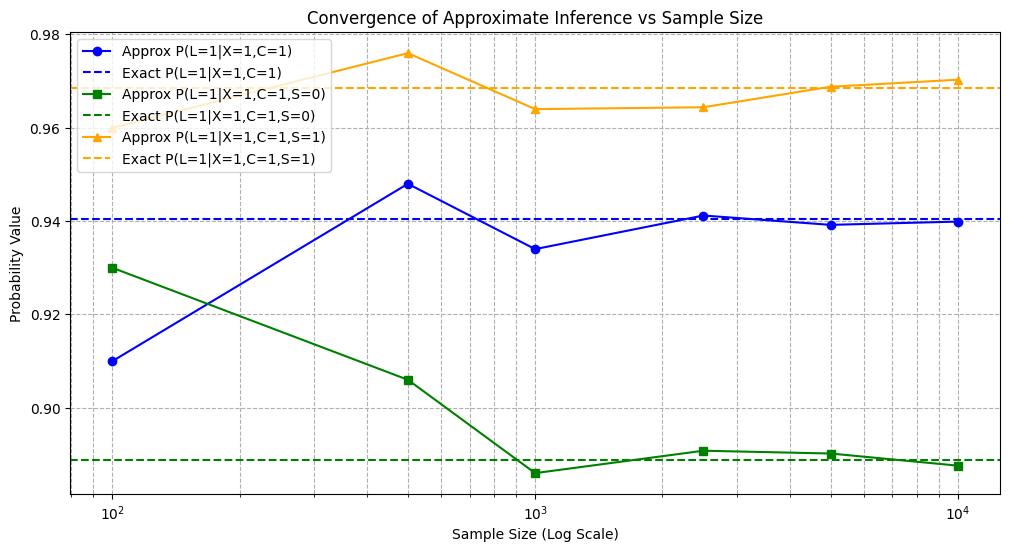

In [6]:
sample_sizes = [100, 500, 1000, 2500, 5000, 10000]
est_q1_list = []
est_q2_list = []
est_q3_list = []

for size in sample_sizes:
    q1, q2, q3 = estimate_approximate(size)
    est_q1_list.append(q1)
    est_q2_list.append(q2)
    est_q3_list.append(q3)

plt.figure(figsize=(12, 6))

# Plot for Q1
plt.plot(sample_sizes, est_q1_list, marker='o', label='Approx P(L=1|X=1,C=1)', color='blue')
plt.axhline(y=p_L1_given_XC, color='blue', linestyle='--', label='Exact P(L=1|X=1,C=1)')

# Plot for Q2
plt.plot(sample_sizes, est_q2_list, marker='s', label='Approx P(L=1|X=1,C=1,S=0)', color='green')
plt.axhline(y=p_L1_given_XCS0, color='green', linestyle='--', label='Exact P(L=1|X=1,C=1,S=0)')

# Plot for Q3
plt.plot(sample_sizes, est_q3_list, marker='^', label='Approx P(L=1|X=1,C=1,S=1)', color='orange')
plt.axhline(y=p_L1_given_XCS1, color='orange', linestyle='--', label='Exact P(L=1|X=1,C=1,S=1)')

plt.xscale('log')
plt.xlabel('Sample Size (Log Scale)')
plt.ylabel('Probability Value')
plt.title('Convergence of Approximate Inference vs Sample Size')
plt.legend()
plt.grid(True, which="both", ls="--")
plt.show()

## Task 5: Compare Exact and Approximate Answers in a Table

In [7]:
# Compare the final exact results and the approximate results with the highest sample size
comparison_df = pd.DataFrame({
    'Query (Probability of Lung Disease)': [
        'P(L=1 | X=1, C=1)',
        'P(L=1 | X=1, C=1, S=0) [Non-Smoker]',
        'P(L=1 | X=1, C=1, S=1) [Smoker]'
    ],
    'Exact (Variable Elimination)': [
        p_L1_given_XC,
        p_L1_given_XCS0,
        p_L1_given_XCS1
    ],
    'Approximate (10,000 Samples)': [
        est_q1_list[-1],
        est_q2_list[-1],
        est_q3_list[-1]
    ]
})

comparison_df['Absolute Difference'] = (comparison_df['Exact (Variable Elimination)'] - comparison_df['Approximate (10,000 Samples)']).abs()
display(comparison_df)

,Query (Probability of Lung Disease),Exact (Variable Elimination),"Approximate (10,000 Samples)",Absolute Difference
0,"P(L=1 | X=1, C=1)",0.940493,0.9399,0.000593
1,"P(L=1 | X=1, C=1, S=0) [Non-Smoker]",0.888889,0.8876,0.001289
2,"P(L=1 | X=1, C=1, S=1) [Smoker]",0.968610,0.9703,0.001690
